# CA2 

In [69]:
import pandas as pd
import numpy as np
import seaborn as sns

In [70]:
data= pd.read_csv("Agri_2025.csv", encoding="latin1")

#### STAGE 1: DATA CLEANING / PREPARATION / STATISTICS / VISUALIZATION

Given that the original dataset originates from the Dirección General del Servicio de Información Agroalimentaria y Pesquera (DGSIAP, 2025) and is in Spanish, the following preprocessing steps will be performed to prepare the data for analysis:

1. Encoding and translation:
   
   The original file will be loaded using "latin1" encoding to preserve special characters. Column headers and key categorical variables ("Irrigation_Modality", "Productive_Cycle", and "Unit") will be translated into English. Proper geographical names (such as "State" and "Municipality") will be kept in their original Spanish form to maintain the official administrative nomenclature.
3. Standaridization of units and handling missing values:
   
   The dataset will be filtered to retain only records measured in metric tons ("Ton") that show a positive harvested area ("Harvested_Area_Ha > 0"). This ensures consistency in measurements and allows for the removal of missing values ("NaN") in the yield and rural price fields—missing values, that arise due to crops that were either not harvested or were damaged.


Once these cleaning stages are complete, descriptive statistics will be examined to understand the distribution of the variables and to guide the selection of appropriate statistical models.

In [71]:
columns_tras={
    "Anio": "Year", 
    "Idestado":"State_ID",
    "Nomestado":"State",
    "Idddr": "ID_DDR",
    "Nomddr":"DDR_Name",
    "Idcader":"ID_CADER",
    "Nomcader":"Name_CADER",
    "Idmunicipio":"Municipality_ID",
    "Nommunicipio":"Municipality_Name",
    "Idciclo":"Cycle_ID",
    "Nomcicloproductivo":"Productive_Cycle",
    "Idmodalidad":"Modality_ID",
    "Nommodalidad":"Irrigation_Modality",
    "Idunidadmedida":"Unit_ID",
    "Nomunidad":"Unit",
    "Idcultivo":"Crop_ID",
    "Nomcultivo":"Crop",
    "Sembrada":"Planted_Area_Ha",
    "Cosechada":"Harvested_Area_Ha",
    "Siniestrada":"Damaged_Area_Ha",
    "Volumenproduccion":"Production_Volume_Ton",
    "Rendimiento":"Yield_Ton_Ha",
    "Preciomediorural":"Avg_Rural_Price_MXN",
    "Valorproduccion":"Production_Value_MXN"
}

df=data.rename(columns=columns_tras)


In [72]:
df.head()

,Year,State_ID,State,ID_DDR,DDR_Name,ID_CADER,Name_CADER,Municipality_ID,Municipality_Name,Cycle_ID,...,Unit,Crop_ID,Crop,Planted_Area_Ha,Harvested_Area_Ha,Damaged_Area_Ha,Production_Volume_Ton,Yield_Ton_Ha,Avg_Rural_Price_MXN,Production_Value_MXN
0,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,...,Tonelada,5490000,Avena forrajera en verde,1500.0,1500.0,0.0,35250.0,23.50,654.00,23053500.00
1,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,...,Tonelada,5670000,Brócoli,50.0,50.0,0.0,850.0,17.00,6887.78,5854613.00
2,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,...,Tonelada,5490000,Avena forrajera en verde,165.0,165.0,0.0,3700.0,22.42,645.00,2386500.00
3,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,...,Tonelada,5670000,Brócoli,60.0,60.0,0.0,785.2,13.09,5161.69,4052958.99
4,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,...,Tonelada,5740000,Calabacita,30.0,30.0,0.0,490.0,16.33,5285.21,2589752.90


In [73]:
df["Irrigation_Modality"].unique()

<ArrowStringArray>
['Riego', 'Temporal']
Length: 2, dtype: str

In [74]:
dfe= df.copy()

dfe["Irrigation_Modality"]= dfe["Irrigation_Modality"].replace({
    "Riego":"Irrigated",
    "Temporal":"Rainfed"
})

dfe["Irrigation_Modality"].unique()

<ArrowStringArray>
['Irrigated', 'Rainfed']
Length: 2, dtype: str

In [75]:
df["Productive_Cycle"].unique()

<ArrowStringArray>
['Otoño-Invierno', 'Primavera-Verano', 'Perennes']
Length: 3, dtype: str

In [76]:
dfe["Productive_Cycle"]= dfe["Productive_Cycle"].replace({
    "Primavera-Verano":"Spring-Summer",
    "Otoño-Invierno":"Autumn-Winter",
    "Perennes":"Perennial"
})

In [77]:
dfe["Productive_Cycle"].unique()

<ArrowStringArray>
['Autumn-Winter', 'Spring-Summer', 'Perennial']
Length: 3, dtype: str

In [78]:
df["Unit"].unique()

<ArrowStringArray>
['Tonelada', 'Metro cuadrado', 'Gruesa', 'Planta', 'Manojo', 'Miles de lts.']
Length: 6, dtype: str

In [79]:
dfe["Unit"]= dfe["Unit"].replace({
    "Tonelada":"Ton",
    "Gruesa":"Gross",
    "Planta":"Plant",
    "Miles de lts":"Thousand_Liters",
    "Manojo":"Bunch",
    "Metro cuadrado":"Square_Meter"
})

dfe["Unit"].unique()

<ArrowStringArray>
['Ton', 'Square_Meter', 'Gross', 'Plant', 'Bunch', 'Miles de lts.']
Length: 6, dtype: str

In [80]:
df["Crop"].unique()

<ArrowStringArray>
[    'Avena forrajera en verde',                      'Brócoli',
                   'Calabacita',                      'Cebolla',
                  'Chile verde',                        'Fresa',
      'Maíz forrajero en verde',                   'Maíz grano',
     'Sorgo forrajero en verde',       'Tomate rojo (jitomate)',
 ...
                      'Quelite',                     'Henequén',
            'Orquídea (planta)',                    'Clyptoria',
                      'Tangelo', 'Ebo (janamargo o veza) grano',
                      'Malanga',                       'Zapupe',
                     'Saramuyo',            'Girasol forrajero']
Length: 314, dtype: str

In [81]:
top_crops_en={
    "Aceituna": "Olive",
    "Acelga": "Swiss Chard",
    "Achiote": "Annatto",
    "Agapando (gruesa)": "Agapanthus (Gross)",
    "Agave": "Agave",
    "Aguacate": "Avocado",
    "Ajo": "Garlic",
    "Ajonjolí": "Sesame",
    "Albahaca": "Basil",
    "Albricia": "Albricia (Apricot Variety)",
    "Alcachofa": "Artichoke",
    "Alcatraz (gruesa)": "Calla Lily (Gross)",
    "Alfalfa achicalada": "Baled Alfalfa",
    "Alfalfa verde": "Green Alfalfa",
    "Algarrobo": "Carob",
    "Algodón hueso": "Seed Cotton (Ginned/Raw)",
    "Alhelí": "Stock Flower",
    "Alhelí (gruesa)": "Stock Flower (Gross)",
    "Alhelí (manojo)": "Stock Flower (Bunch)",
    "Alpiste": "Canary Seed",
    "Alstroemeria (gruesa)": "Alstroemeria (Gross)",
    "Amaranto": "Amaranth",
    "Anturios (gruesa)": "Anthurium (Gross)",
    "Anís": "Anise",
    "Apio": "Celery",
    "Aretillo (planta)": "Fuchsia (Plant)",
    "Arrayán": "Myrtle",
    "Arroz palay": "Paddy Rice",
    "Arvejón": "Field Pea",
    "Arándano": "Blueberry",
    "Aster (manojo)": "Aster (Bunch)",
    "Ave del paraíso (gruesa)": "Bird of Paradise (Gross)",
    "Avena forrajera achicalada": "Baled Forage Oats",
    "Avena forrajera en verde": "Green Forage Oats",
    "Avena grano": "Grain Oats",
    "Baby back choi": "Baby Bok Choy",
    "Bambú": "Bamboo",
    "Bangaña": "Bangana",
    "Begonia (planta)": "Begonia (Plant)",
    "Belén (planta)": "Impatiens (Plant)",
    "Berenjena": "Eggplant",
    "Betabel": "Beetroot",
    "Boi choi": "Bok Choy",
    "Brócoli": "Broccoli",
    "Cacahuate": "Peanut",
    "Cacao": "Cacao",
    "Café cereza": "Coffee Cherry",
    "Caimito": "Star Apple (Caimito)",
    "Calabacita": "Zucchini",
    "Calabaza": "Pumpkin / Squash",
    "Calabaza semilla o chihua": "Seed Squash (Chihua)",
    "Calancoe (planta)": "Kalanchoe (Plant)",
    "Camote": "Sweet Potato",
    "Canola": "Canola",
    "Capulín": "Capulin Cherry",
    "Carambolo": "Starfruit",
    "Caña de azúcar": "Sugarcane",
    "Caña de azúcar forrajera": "Forage Sugarcane",
    "Caña de azúcar fruta": "Table Sugarcane",
    "Caña de azúcar piloncillo": "Sugarcane for Piloncillo",
    "Cebada forrajera achicalada": "Baled Forage Barley",
    "Cebada forrajera en verde": "Green Forage Barley",
    "Cebada grano": "Grain Barley",
    "Cebolla": "Onion",
    "Centeno grano": "Grain Rye",
    "Cereza": "Cherry",
    "Chabacano": "Apricot",
    "Chayote": "Chayote",
    "Chilacayote": "Fig-Leaf Gourd (Chilacayote)",
    "Chile seco": "Dried Chili",
    "Chile verde": "Green Chili",
    "Chirimoya": "Cherimoya",
    "Chives": "Chives",
    "Chía": "Chia",
    "Chícharo": "Green Pea",
    "Cilantro": "Cilantro",
    "Cineraria (planta)": "Cineraria (Plant)",
    "Ciruela": "Plum",
    "Clavel (gruesa)": "Carnation (Gross)",
    "Clyptoria": "Clyptoria",
    "Coco fruta": "Coconut Fruit",
    "Col (repollo)": "Cabbage",
    "Col de bruselas": "Brussels Sprouts",
    "Coliflor": "Cauliflower",
    "Comino": "Cumin",
    "Copra": "Copra",
    "Coquia": "Coquia",
    "Crisantemo (gruesa)": "Chrysanthemum (Gross)",
    "Crisantemo (planta)": "Chrysanthemum (Plant)",
    "Cyclamen (planta)": "Cyclamen (Plant)",
    "Cártamo": "Safflower",
    "Cártamo forrajero en verde": "Green Forage Safflower",
    "Cítricos": "Citrus",
    "Dalia (planta)": "Dahlia (Plant)",
    "Durazno": "Peach",
    "Dátil": "Date",
    "Dólar (manojo)": "Silver Dollar Eucalyptus (Bunch)",
    "Ebo (janamargo o veza)": "Vetch (Ebo)",
    "Ebo (janamargo o veza) grano": "Vetch Grain (Ebo)",
    "Ejote": "Green Bean",
    "Elote": "Sweet Corn / Cob Corn",
    "Eneldo": "Dill",
    "Epazote": "Epazote",
    "Especias y medicinales": "Spices and Medicinal Plants",
    "Espinaca": "Spinach",
    "Espárrago": "Asparagus",
    "Estropajo": "Loofah",
    "Eucalipto": "Eucalyptus",
    "Flor cera": "Waxflower",
    "Flor perrito": "Snapdragon",
    "Flores": "Flowers",
    "Frambuesa": "Raspberry",
    "Fresa": "Strawberry",
    "Frijol": "Bean",
    "Frijol forrajero": "Forage Bean",
    "Frijol x pelón": "Cowpea (Xpelon)",
    "Frutales varios": "Miscellaneous Fruit Trees",
    "Gai lan (kay laan)": "Gai Lan (Chinese Broccoli)",
    "Garbanzo forrajero": "Forage Chickpea",
    "Garbanzo grano": "Grain Chickpea",
    "Garbanzo porquero": "Feed Chickpea (Garbanzo Porquero)",
    "Geranio (planta)": "Geranium (Plant)",
    "Gerbera (gruesa)": "Gerbera (Gross)",
    "Girasol": "Sunflower",
    "Girasol flor (gruesa)": "Cut Sunflower (Gross)",
    "Girasol forrajero": "Forage Sunflower",
    "Gladiola (gruesa)": "Gladiolus (Gross)",
    "Granada": "Pomegranate",
    "Guaje": "River Tamarind (Guaje)",
    "Guamúchil": "Manila Tamarind (Guamuchil)",
    "Guanábana": "Soursop",
    "Guayaba": "Guava",
    "Haba grano": "Grain Fava Bean",
    "Haba verde": "Green Fava Bean",
    "Helecho (manojo)": "Fern (Bunch)",
    "Helecho (planta)": "Fern (Plant)",
    "Henequén": "Henequen",
    "Hierbabuena": "Spearmint",
    "Higo": "Fig",
    "Hoja de plátano (belillo)": "Banana Leaf",
    "Hongos, setas y champiñones": "Mushrooms",
    "Hortalizas": "Vegetables",
    "Hortensia (planta)": "Hydrangea (Plant)",
    "Huauzontle": "Huauzontle (Mexican Goosefoot)",
    "Hule hevea": "Rubber Tree (Hevea)",
    "Inmortal (manojo)": "Strawflower (Bunch)",
    "Jaca (jackfruit)": "Jackfruit",
    "Jamaica": "Hibiscus (Jamaica)",
    "Jatropha": "Jatropha",
    "Jengibre": "Ginger",
    "Jícama": "Jicama",
    "Kale": "Kale",
    "Kohlrabi": "Kohlrabi",
    "Lechuga": "Lettuce",
    "Lenteja": "Lentil",
    "Lilium (gruesa)": "Lily (Gross)",
    "Lilium (planta)": "Lily (Plant)",
    "Lima": "Sweet Lime",
    "Limonium (manojo)": "Limonium (Bunch)",
    "Limón": "Lemon / Lime",
    "Limón real": "Key Lime / Sweet Lemon (Limon Real)",
    "Litchi": "Lychee",
    "Macadamia": "Macadamia",
    "Maguey": "Maguey",
    "Maguey forrajero": "Forage Maguey",
    "Maguey mixiotero": "Mixiote Maguey",
    "Maguey pulquero (miles de lts.)": "Pulque Maguey (Thousand Liters)",
    "Malanga": "Taro (Malanga)",
    "Mamey": "Mamey Sapote",
    "Mandarina": "Mandarin / Tangerine",
    "Mango": "Mango",
    "Mangostán": "Mangosteen",
    "Mano de león": "Lion's Ear",
    "Mano de león (manojo)": "Lion's Ear (Bunch)",
    "Manzana": "Apple",
    "Manzanilla": "Chamomile",
    "Maracuyá": "Passion Fruit",
    "Marañón": "Cashew",
    "Margarita": "Daisy",
    "Margarita (manojo)": "Daisy (Bunch)",
    "Maíz forrajero en verde": "Green Forage Corn",
    "Maíz forrajero seco": "Dry Forage Corn",
    "Maíz grano": "Grain Corn",
    "Mejorana": "Marjoram",
    "Melón": "Melon",
    "Melón amargo": "Bitter Melon",
    "Membrillo": "Quince",
    "Menta": "Mint",
    "Moringa": "Moringa",
    "Nabo": "Turnip",
    "Nabo forrajero": "Forage Turnip",
    "Nanche": "Nanche",
    "Napa": "Napa Cabbage",
    "Naranja": "Orange",
    "Nardo (gruesa)": "Tuberose (Gross)",
    "Nochebuena (planta)": "Poinsettia (Plant)",
    "Noni": "Noni",
    "Nopal forrajero": "Forage Prickly Pear (Nopal)",
    "Nopalitos": "Cactus Pads (Nopalitos)",
    "Nube": "Baby's Breath",
    "Nube (manojo)": "Baby's Breath (Bunch)",
    "Nuez": "Walnut / Pecan",
    "Níspero": "Loquat",
    "Okra (angú o gombo)": "Okra",
    "Orquídea (gruesa)": "Orchid (Gross)",
    "Orquídea (planta)": "Orchid (Plant)",
    "Orégano": "Oregano",
    "Palma africana o de aceite": "Oil Palm",
    "Palma camedor (gruesa)": "Parlor Palm (Gross)",
    "Palma de ornato": "Ornamental Palm",
    "Palma de ornato (planta)": "Ornamental Palm (Plant)",
    "Palma taco": "Palm Heart / Taco Palm",
    "Papa": "Potato",
    "Papaya": "Papaya",
    "Pasto tapete (m2)": "Turfgrass (Sq. Meter)",
    "Pastos y praderas": "Pastures and Grasslands",
    "Pastos y praderas achicalado": "Baled Pastures and Grasslands",
    "Pensamiento (planta)": "Pansy (Plant)",
    "Pepino": "Cucumber",
    "Pera": "Pear",
    "Perejil": "Parsley",
    "Persimonio": "Persimmon",
    "Perón": "Peron Apple",
    "Petunia (planta)": "Petunia (Plant)",
    "Pimienta": "Black Pepper / Allspice",
    "Pipicha": "Pipicha (Pápalo/Herb)",
    "Pistache": "Pistachio",
    "Pitahaya": "Dragon Fruit (Pitahaya)",
    "Pitaya": "Pitaya Cactus Fruit",
    "Piña": "Pineapple",
    "Piñón": "Pine Nut",
    "Plantas de ornato (planta)": "Ornamental Plants (Plant)",
    "Plantero de tabaco (planta)": "Tobacco Seedling (Plant)",
    "Plátano": "Banana",
    "Polar": "Polar Flower",
    "Polar (gruesa)": "Polar Flower (Gross)",
    "Pon-pon (gruesa)": "Pom-Pom Flower (Gross)",
    "Poro (leek)": "Leek",
    "Pápalo": "Papalo",
    "Quelite": "Quelite (Wild Leafy Greens)",
    "Rambután": "Rambutan",
    "Romerito": "Romerito (Seablite)",
    "Romero": "Rosemary",
    "Rosa": "Rose",
    "Rosa (gruesa)": "Rose (Gross)",
    "Rosa (planta)": "Rose (Plant)",
    "Rábano": "Radish",
    "Salvia": "Sage",
    "Sandía": "Watermelon",
    "Saramuyo": "Sugar Apple (Saramuyo)",
    "Semilla de avena grano": "Grain Oat Seed",
    "Semilla de caña de azúcar": "Sugarcane Seed",
    "Semilla de cebada grano": "Grain Barley Seed",
    "Semilla de frijol": "Bean Seed",
    "Semilla de garbanzo grano": "Grain Chickpea Seed",
    "Semilla de garbanzo porquero": "Feed Chickpea Seed",
    "Semilla de haba": "Fava Bean Seed",
    "Semilla de jícama": "Jicama Seed",
    "Semilla de maíz grano": "Grain Corn Seed",
    "Semilla de papa": "Seed Potato",
    "Semilla de pastos y praderas": "Pasture and Grassland Seed",
    "Semilla de sorgo grano": "Grain Sorghum Seed",
    "Semilla de soya": "Soybean Seed",
    "Semilla de tomate rojo (jitomate)": "Red Tomato Seed",
    "Semilla de trigo grano": "Grain Wheat Seed",
    "Semilla de triticale grano": "Grain Triticale Seed",
    "Shangai-bock-choy": "Shanghai Bok Choy",
    "Shop suey": "Chop Suey Greens",
    "Solidago (manojo)": "Solidago / Goldenrod (Bunch)",
    "Sorgo escobero": "Broom Sorghum",
    "Sorgo forrajero achicalado": "Baled Forage Sorghum",
    "Sorgo forrajero en verde": "Green Forage Sorghum",
    "Sorgo forrajero seco": "Dry Forage Sorghum",
    "Sorgo grano": "Grain Sorghum",
    "Soya": "Soybean",
    "Statice": "Statice",
    "Statice (manojo)": "Statice (Bunch)",
    "Stevia": "Stevia",
    "Sábila": "Aloe Vera",
    "Tabaco": "Tobacco",
    "Tamarindo": "Tamarind",
    "Tangelo": "Tangelo",
    "Tangerina": "Tangerine",
    "Tarragón": "Tarragon",
    "Tejocote": "Tejocote (Mexican Hawthorn)",
    "Terciopelo (manojo)": "Celosia / Cockscomb (Bunch)",
    "Tomate rojo (jitomate)": "Red Tomato",
    "Tomate verde": "Green Tomatillo",
    "Tomillo": "Thyme",
    "Toronja (pomelo)": "Grapefruit",
    "Trigo forrajero verde": "Green Forage Wheat",
    "Trigo grano": "Grain Wheat",
    "Triticale forrajero en verde": "Green Forage Triticale",
    "Triticale grano": "Grain Triticale",
    "Trébol": "Clover",
    "Tulipán holandés": "Dutch Tulip",
    "Tuna": "Prickly Pear Fruit (Tuna)",
    "Té limón": "Lemongrass",
    "Uva": "Grape",
    "Vainilla": "Vanilla",
    "Verdolaga": "Purslane",
    "Viveros de durazno": "Peach Nurseries",
    "Viveros de manzana": "Apple Nurseries",
    "Viveros de nuez": "Walnut Nurseries",
    "Yu-choy": "Yu Choy",
    "Yuca alimenticia": "Cassava",
    "Zanahoria": "Carrot",
    "Zapote": "Sapote",
    "Zapupe": "Zapupe (Agave Fiber)",
    "Zarzamora": "Blackberry",
    "Zempoalxochitl": "Marigold (Zempoalxochitl)",
    "Zempoalxochitl (manojo)": "Marigold (Bunch)",
    "Zempoalxochitl (planta)": "Marigold (Plant)",
    "Árbol de navidad (planta)": "Christmas Tree (Plant)",
}

dfe["Crop"]=df["Crop"].replace(top_crops_en)

In [82]:
dfe["Crop"].value_counts().head(10)

Crop
Grain Corn                 4558
Bean                       2642
Green Forage Oats          1503
Pastures and Grasslands    1355
Red Tomato                 1145
Green Chili                 861
Grain Sorghum               846
Green Forage Corn           783
Avocado                     774
Green Tomatillo             759
Name: count, dtype: int64

###### NOTE: The crop column contains 314 unique crops. To ensure that visualizations and summaries remain clear and readable, we will use only the 10 most frequent crops (based on the number of records).

In [83]:
dfe.head()

,Year,State_ID,State,ID_DDR,DDR_Name,ID_CADER,Name_CADER,Municipality_ID,Municipality_Name,Cycle_ID,...,Unit,Crop_ID,Crop,Planted_Area_Ha,Harvested_Area_Ha,Damaged_Area_Ha,Production_Volume_Ton,Yield_Ton_Ha,Avg_Rural_Price_MXN,Production_Value_MXN
0,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,...,Ton,5490000,Green Forage Oats,1500.0,1500.0,0.0,35250.0,23.50,654.00,23053500.00
1,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,...,Ton,5670000,Broccoli,50.0,50.0,0.0,850.0,17.00,6887.78,5854613.00
2,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,...,Ton,5490000,Green Forage Oats,165.0,165.0,0.0,3700.0,22.42,645.00,2386500.00
3,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,...,Ton,5670000,Broccoli,60.0,60.0,0.0,785.2,13.09,5161.69,4052958.99
4,2025,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,1,Aguascalientes,2,...,Ton,5740000,Zucchini,30.0,30.0,0.0,490.0,16.33,5285.21,2589752.90


In [86]:
dfe.isnull().sum()

Year                       0
State_ID                   0
State                      0
ID_DDR                     0
DDR_Name                   0
ID_CADER                   0
Name_CADER                 0
Municipality_ID            0
Municipality_Name          0
Cycle_ID                   0
Productive_Cycle           0
Modality_ID                0
Irrigation_Modality        0
Unit_ID                    0
Unit                       0
Crop_ID                    0
Crop                       0
Planted_Area_Ha            0
Harvested_Area_Ha          0
Damaged_Area_Ha            0
Production_Volume_Ton      0
Yield_Ton_Ha             415
Avg_Rural_Price_MXN      415
Production_Value_MXN       0
dtype: int64

In [87]:
dfe.duplicated().sum()

np.int64(0)

In [88]:
dfe["Unit"].value_counts()

Unit
Ton              35310
Gross              266
Plant              133
Miles de lts.      104
Bunch               72
Square_Meter        17
Name: count, dtype: int64

#### Standardization of units:

Out of a total of 35,921 records, "tons" (Ton) account for 35,310 rows (98.3%), while units other than tons (gross units, plants, thousands of liters, bunches, and square meters) represent, in total, only 611 rows (1.7%).

Therefore, we will henceforth consider only tons, to ensure that comparisons of volume, yield, and price are consistent across all records. 

Subsequently, we remove the null values from our columns.

In [91]:
dfe= dfe[dfe["Unit"] == "Ton"]

In [93]:
dfe= dfe.dropna(subset=["Yield_Ton_Ha", "Avg_Rural_Price_MXN"])

In [95]:
dfe.isnull().sum()

Year                     0
State_ID                 0
State                    0
ID_DDR                   0
DDR_Name                 0
ID_CADER                 0
Name_CADER               0
Municipality_ID          0
Municipality_Name        0
Cycle_ID                 0
Productive_Cycle         0
Modality_ID              0
Irrigation_Modality      0
Unit_ID                  0
Unit                     0
Crop_ID                  0
Crop                     0
Planted_Area_Ha          0
Harvested_Area_Ha        0
Damaged_Area_Ha          0
Production_Volume_Ton    0
Yield_Ton_Ha             0
Avg_Rural_Price_MXN      0
Production_Value_MXN     0
dtype: int64

In [97]:
dfe.shape

(34906, 24)

In [98]:
dfe.describe()

,Year,State_ID,ID_DDR,ID_CADER,Municipality_ID,Cycle_ID,Modality_ID,Unit_ID,Crop_ID,Planted_Area_Ha,Harvested_Area_Ha,Damaged_Area_Ha,Production_Volume_Ton,Yield_Ton_Ha,Avg_Rural_Price_MXN,Production_Value_MXN
count,34906.0,34906.000000,34906.000000,34906.000000,34906.000000,34906.000000,34906.000000,34906.0,3.490600e+04,34906.000000,34906.000000,34906.000000,3.490600e+04,34906.000000,34906.000000,3.490600e+04
mean,2025.0,18.328454,98.629605,2.667879,82.305363,2.062310,1.452845,200201.0,7.402894e+06,566.716391,547.038915,4.964518,7.070232e+03,18.484478,9298.517181,2.281468e+07
std,0.0,7.531191,47.945028,1.938865,111.363569,0.757363,0.497779,0.0,1.946569e+06,2599.026370,2560.128666,106.157450,4.719028e+04,31.031854,16426.658554,1.138831e+08
min,2025.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,200201.0,1.500000e+06,0.040000,0.040000,0.000000,6.000000e-02,0.080000,125.000000,4.075200e+02
25%,2025.0,13.000000,63.000000,1.000000,16.000000,1.000000,1.000000,200201.0,6.060000e+06,10.000000,9.550000,0.000000,6.493250e+01,2.670000,4045.082500,4.124732e+05
50%,2025.0,19.000000,104.000000,2.000000,42.000000,2.000000,1.000000,200201.0,7.390000e+06,38.635000,37.000000,0.000000,3.371750e+02,9.140000,6085.205000,1.705962e+06
75%,2025.0,23.000000,126.000000,3.000000,98.000000,3.000000,2.000000,200201.0,8.130000e+06,210.000000,200.000000,0.000000,1.856075e+03,21.250000,9618.430000,8.451818e+06
max,2025.0,32.000000,193.000000,19.000000,570.000000,3.000000,2.000000,200201.0,1.507000e+07,179125.500000,179125.500000,9933.000000,2.020028e+06,1516.670000,650000.000000,4.968507e+09


In [100]:
num_var =[
    "Planted_Area_Ha",
    "Harvested_Area_Ha",
    "Damaged_Area_Ha",
    "Production_Volume_Ton",
    "Yield_Ton_Ha",
    "Avg_Rural_Price_MXN",
    "Production_Value_MXN"
]

dfe[num_var].describe().T
    
    

,count,mean,std,min,25%,50%,75%,max
Planted_Area_Ha,34906.0,5.667164e+02,2.599026e+03,0.04,10.0000,38.635,2.100000e+02,1.791255e+05
Harvested_Area_Ha,34906.0,5.470389e+02,2.560129e+03,0.04,9.5500,37.000,2.000000e+02,1.791255e+05
Damaged_Area_Ha,34906.0,4.964518e+00,1.061574e+02,0.00,0.0000,0.000,0.000000e+00,9.933000e+03
Production_Volume_Ton,34906.0,7.070232e+03,4.719028e+04,0.06,64.9325,337.175,1.856075e+03,2.020028e+06
Yield_Ton_Ha,34906.0,1.848448e+01,3.103185e+01,0.08,2.6700,9.140,2.125000e+01,1.516670e+03
Avg_Rural_Price_MXN,34906.0,9.298517e+03,1.642666e+04,125.00,4045.0825,6085.205,9.618430e+03,6.500000e+05
Production_Value_MXN,34906.0,2.281468e+07,1.138831e+08,407.52,412473.2425,1705962.230,8.451818e+06,4.968507e+09


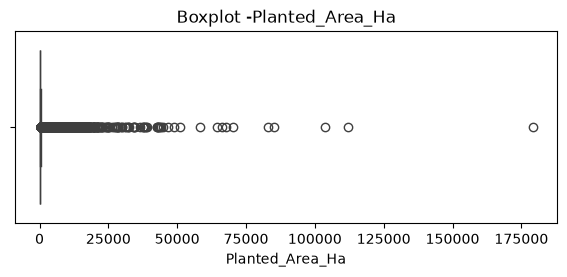

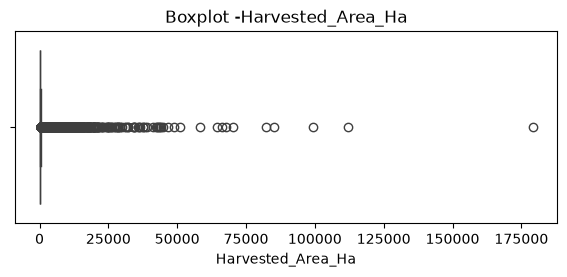

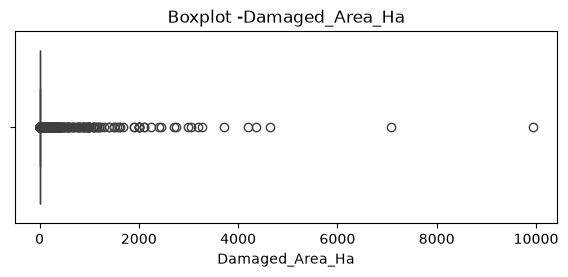

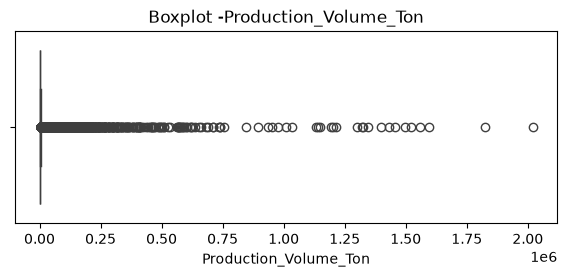

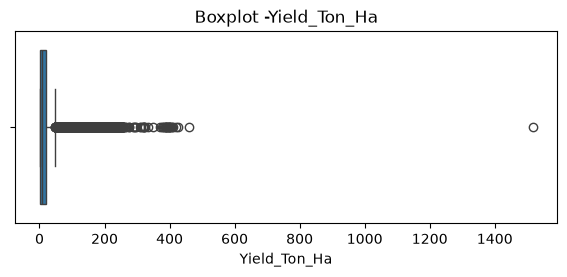

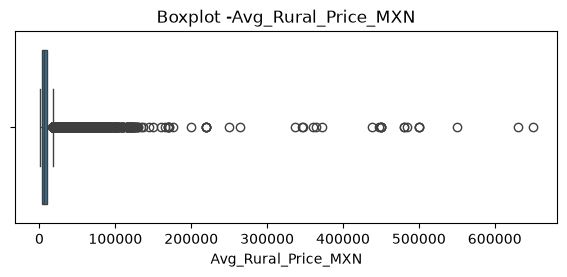

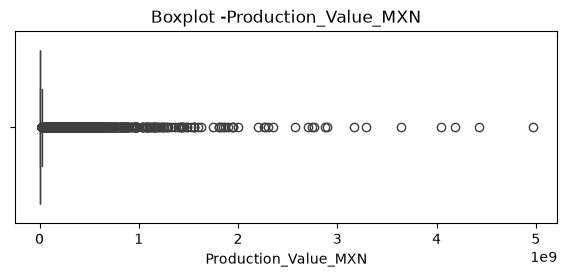

In [103]:
import matplotlib.pyplot as plt

for col in num_var:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(data=dfe, x=col)
    plt.title(f"Boxplot -{col}")
    plt.xlabel(col)
    plt.show()

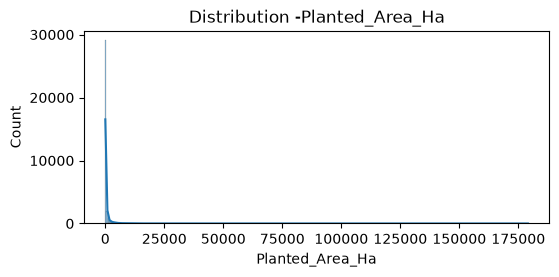

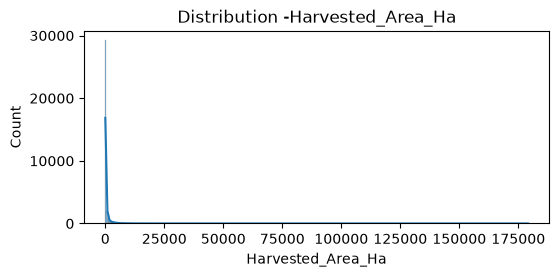

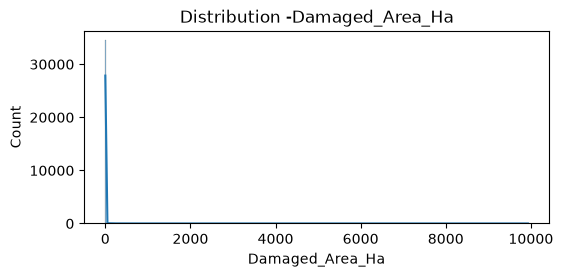

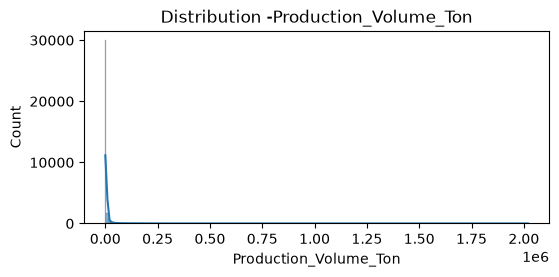

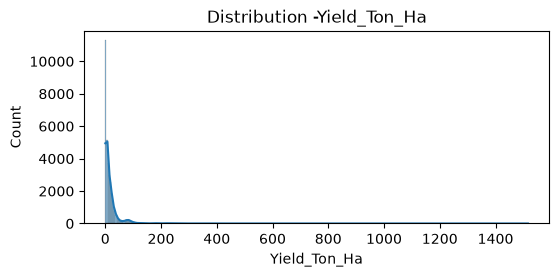

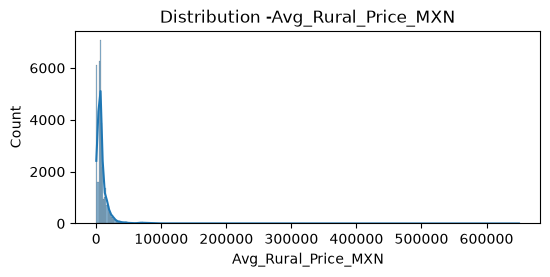

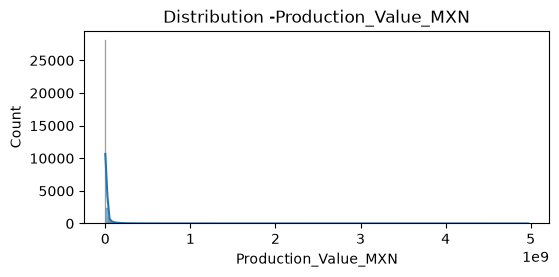

In [104]:

for col in num_var:
    plt.figure(figsize=(6, 2.5))
    sns.histplot(dfe[col], kde=True)
    plt.title(f"Distribution -{col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

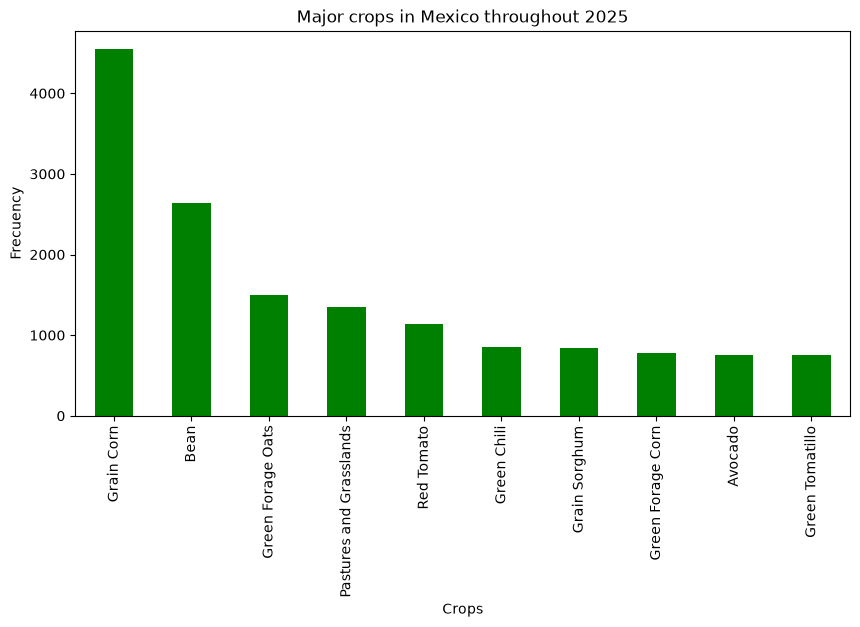

In [112]:
top_crops=dfe["Crop"].value_counts().head(10).plot(kind='bar', figsize=(10,5), color='green')
plt.title('Major crops in Mexico throughout 2025')
plt.ylabel('Frecuency')
plt.xlabel('Crops')
plt.show()


In [109]:
top_crops=dfe["Crop"].value_counts().head(10)
top_crops

Crop
Grain Corn                 4548
Bean                       2638
Green Forage Oats          1501
Pastures and Grasslands    1348
Red Tomato                 1141
Green Chili                 852
Grain Sorghum               839
Green Forage Corn           783
Avocado                     758
Green Tomatillo             756
Name: count, dtype: int64

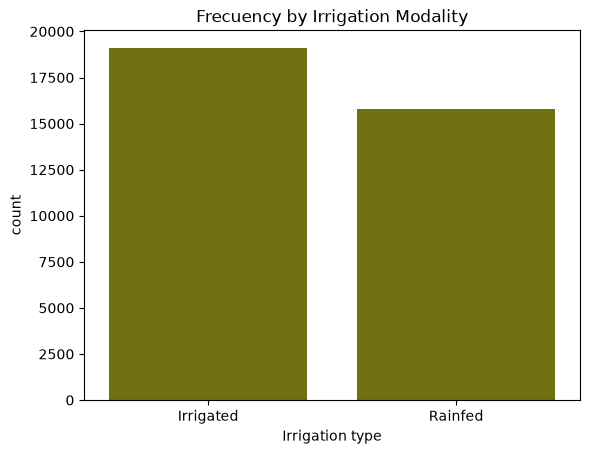

In [119]:
sns.countplot(data=dfe, x="Irrigation_Modality", color='olive')
plt.title("Frecuency by Irrigation Modality")
plt.xlabel("Irrigation type")
plt.show()

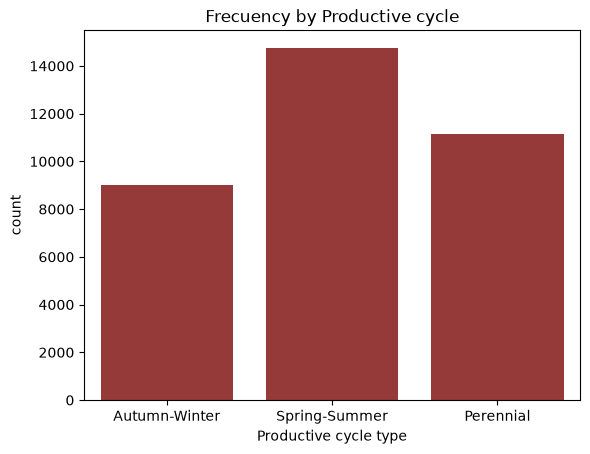

In [118]:
sns.countplot(data=dfe, x="Productive_Cycle", color='brown')
plt.title("Frecuency by Productive cycle")
plt.xlabel("Productive cycle type")
plt.show()

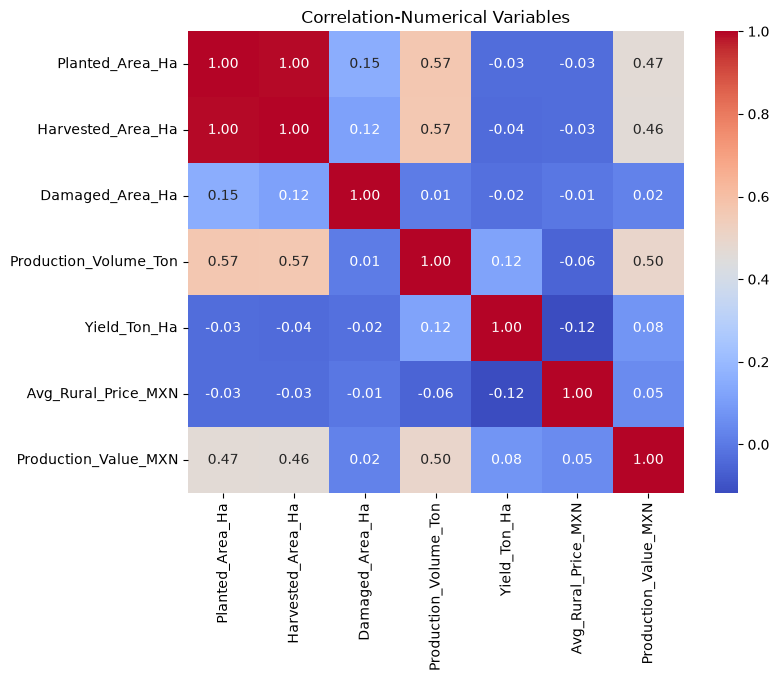

In [123]:
num_var =[
    "Planted_Area_Ha",
    "Harvested_Area_Ha",
    "Damaged_Area_Ha",
    "Production_Volume_Ton",
    "Yield_Ton_Ha",
    "Avg_Rural_Price_MXN",
    "Production_Value_MXN"
]

corr= dfe[num_var].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation-Numerical Variables")
plt.show()

#### STAGE 2: INFERENTIAL STATISTICS

### REFERENCES

Dirección General del Servicio de Información Agroalimentaria y Pesquera (DGSIAP) (2025) Cierre de la Producción Agrícola 2025 [Dataset]. Secretaría de Agricultura y Desarrollo Rural (SADER). Available at: https://nube.agricultura.gob.mx/datosAbiertos/Agricola.php (Accessed: 25 November 2026).